# Executive summary

## This document presents a two part process consisting of gathering data from scratch, merging, cleaning and brief exploratory analysis that uncover some insights about courses performance.

The raw data was obtained through browser DevTools from answers to the fetch requests on [DataCamp course catalog](https://www.datacamp.com/courses-all).  Initially there are 21 JSON files that were downloaded, next steps are presented in this Notebook.

In analysis section I stated a question to follow through:

- *Which technology attract the most interest? Which technology has the highest student retention?*

## Key insights:
- While Python drives the highest volume of students (\~460k starts), the Theory courses achieve superior renention (~60%)
- Technologies like Git, Github, DVC exhibit exceptional completion rates, despite lower number of starts. They can serve as role model courses.
- Identified n8n as a critical outlier with lowest retention among all technologies. Requesting immediate reaction.

# Import and data cleaning

## Data cleaning

### Loading and merging files

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)

sns.set_style('darkgrid')

In [3]:
df_part1 = pd.read_json('courses_all_p1.json')
df_part1.head()

,results
0,"{'hits': [{'objectid_distinct': 'course-735', ..."
1,"{'hits': [], 'nbHits': 619, 'page': 0, 'nbPage..."
2,"{'hits': [], 'nbHits': 619, 'page': 0, 'nbPage..."


In [4]:
# Quick check does json_normalize works as intended
df_part1 = pd.json_normalize(df_part1.loc[0, 'results'], record_path='hits')
df_part1.head()

,objectid_distinct,content_id,content_category,skill_level,languages_array,technology_array,topic_array,rating_int,rating_array,date_launched_array,duration_string,role_array,industry_array,starts_int,completions_int,rating_float,date_launched_date,duration_float,authors_array,url,content_id_parent,url_parent,title_parent,nb_courses_int,nb_projects_int,paid,mobile_enabled,is_labeled_as_new,has_variant_traditional,has_variant_ai_native,assessment_stage,content_type_priority,row_hash,row_hash_stats_updates,objectID,title.en-US,title.it-IT,title.tr-TR,title.fr-FR,title.pt-BR,title.de-DE,title.es-ES,title.id-ID,title.nl-NL,content_type.en-US,content_type.es-ES,content_type.pt-BR,content_type.de-DE,short_description.en-US,short_description.tr-TR,short_description.fr-FR,short_description.pt-BR,short_description.de-DE,short_description.es-ES,description.en-US,description.it-IT,description.tr-TR,description.fr-FR,description.pt-BR,description.de-DE,description.es-ES,description.id-ID,description.nl-NL,skill_technology_content_type.en-US,_highlightResult.title.en-US.value,_highlightResult.title.en-US.matchLevel,_highlightResult.title.en-US.matchedWords,_highlightResult.title.it-IT.value,_highlightResult.title.it-IT.matchLevel,_highlightResult.title.it-IT.matchedWords,_highlightResult.title.tr-TR.value,_highlightResult.title.tr-TR.matchLevel,_highlightResult.title.tr-TR.matchedWords,_highlightResult.title.fr-FR.value,_highlightResult.title.fr-FR.matchLevel,_highlightResult.title.fr-FR.matchedWords,_highlightResult.title.pt-BR.value,_highlightResult.title.pt-BR.matchLevel,_highlightResult.title.pt-BR.matchedWords,_highlightResult.title.de-DE.value,_highlightResult.title.de-DE.matchLevel,_highlightResult.title.de-DE.matchedWords,_highlightResult.title.es-ES.value,_highlightResult.title.es-ES.matchLevel,_highlightResult.title.es-ES.matchedWords,_highlightResult.title.id-ID.value,_highlightResult.title.id-ID.matchLevel,_highlightResult.title.id-ID.matchedWords,_highlightResult.title.nl-NL.value,_highlightResult.title.nl-NL.matchLevel,_highlightResult.title.nl-NL.matchedWords,_highlightResult.content_type.en-US.value,_highlightResult.content_type.en-US.matchLevel,_highlightResult.content_type.en-US.matchedWords,_highlightResult.content_type.es-ES.value,_highlightResult.content_type.es-ES.matchLevel,_highlightResult.content_type.es-ES.matchedWords,_highlightResult.content_type.pt-BR.value,_highlightResult.content_type.pt-BR.matchLevel,_highlightResult.content_type.pt-BR.matchedWords,_highlightResult.content_type.de-DE.value,_highlightResult.content_type.de-DE.matchLevel,_highlightResult.content_type.de-DE.matchedWords,_highlightResult.technology_array,_highlightResult.topic_array,_highlightResult.authors_array,_highlightResult.short_description.en-US.value,_highlightResult.short_description.en-US.matchLevel,_highlightResult.short_description.en-US.matchedWords,_highlightResult.short_description.tr-TR.value,_highlightResult.short_description.tr-TR.matchLevel,_highlightResult.short_description.tr-TR.matchedWords,_highlightResult.short_description.fr-FR.value,_highlightResult.short_description.fr-FR.matchLevel,_highlightResult.short_description.fr-FR.matchedWords,_highlightResult.short_description.pt-BR.value,_highlightResult.short_description.pt-BR.matchLevel,_highlightResult.short_description.pt-BR.matchedWords,_highlightResult.short_description.de-DE.value,_highlightResult.short_description.de-DE.matchLevel,_highlightResult.short_description.de-DE.matchedWords,_highlightResult.short_description.es-ES.value,_highlightResult.short_description.es-ES.matchLevel,_highlightResult.short_description.es-ES.matchedWords,_highlightResult.description.en-US.value,_highlightResult.description.en-US.matchLevel,_highlightResult.description.en-US.matchedWords,_highlightResult.description.it-IT.value,_highlightResult.description.it-IT.matchLevel,_highlightResult.description.it-IT.matchedWords,_highlightResult.description.tr-TR.value,_highlightResult.descriptio

In [5]:
all_partial_dfs = []

for part in range(1,22):
  df_temp = pd.read_json(f'courses_all_p{part}.json')
  df_temp = pd.json_normalize(df_temp.loc[0, 'results'], record_path='hits')
  all_partial_dfs.append(df_temp)

df_concated = pd.concat(all_partial_dfs, ignore_index=True)

# quick check, expecting 619 courses and 166 columns
df_concated.shape

(619, 166)

### Getting rid of unnecessary columns

In [6]:
# columns refering to non-english titles/description etc.
regex_col_pattern = '|'.join(['tr-TR', 'it-IT', 'fr-FR', 'pt-BR', 'de-DE', 'es-ES', 'id-ID', 'nl-NL'])

non_eng_columns = df_concated.filter(regex=regex_col_pattern)

df_trunc = df_concated.drop(columns=non_eng_columns.columns)

In [7]:
# after inspecting .info() dropping 0 non-null columns
null_coll = ['content_id_parent', 'url_parent', 'title_parent', 'nb_courses_int', 'nb_projects_int', 'assessment_stage']

In [8]:
# let's inspect if some of the columns are non-informative
for i in df_trunc.columns:
  counting = df_trunc[i].value_counts()
  if len(counting) == 1:
    print(counting)

content_category
learn    619
Name: count, dtype: int64
role_array
[]    619
Name: count, dtype: int64
industry_array
[]    619
Name: count, dtype: int64
has_variant_traditional
True    619
Name: count, dtype: int64
content_type_priority
1.0    619
Name: count, dtype: int64
content_type.en-US
course    619
Name: count, dtype: int64
_highlightResult.title.en-US.matchLevel
none    619
Name: count, dtype: int64
_highlightResult.title.en-US.matchedWords
[]    619
Name: count, dtype: int64
_highlightResult.content_type.en-US.value
course    619
Name: count, dtype: int64
_highlightResult.content_type.en-US.matchLevel
none    619
Name: count, dtype: int64
_highlightResult.content_type.en-US.matchedWords
[]    619
Name: count, dtype: int64
_highlightResult.short_description.en-US.matchLevel
none    619
Name: count, dtype: int64
_highlightResult.short_description.en-US.matchedWords
[]    619
Name: count, dtype: int64
_highlightResult.description.en-US.matchLevel
none    619
Name: count, dtype: 

In [9]:
# Dropping columns with only one value from previous cell output
one_value_col = ['content_category', 'role_array', 'industry_array', 'has_variant_traditional', 'content_type_priority', 'content_type.en-US', '_highlightResult.title.en-US.matchLevel', '_highlightResult.title.en-US.matchedWords', '_highlightResult.content_type.en-US.value', '_highlightResult.content_type.en-US.matchLevel', '_highlightResult.content_type.en-US.matchedWords', '_highlightResult.short_description.en-US.matchLevel', '_highlightResult.short_description.en-US.matchedWords', '_highlightResult.description.en-US.matchLevel', '_highlightResult.description.en-US.matchedWords', '_highlightResult.skill_technology_content_type.en-US.matchLevel', '_highlightResult.skill_technology_content_type.en-US.matchedWords']

In [10]:
df_trunc = df_trunc.drop(columns=null_coll + one_value_col)

In [11]:
# Removing redundant columns
redundant_col = [
    '_highlightResult.title.en-US.value', '_highlightResult.technology_array', '_highlightResult.topic_array', '_highlightResult.authors_array', '_highlightResult.short_description.en-US.value', '_highlightResult.description.en-US.value', '_highlightResult.skill_technology_content_type.en-US.value', 'content_id', 'objectID',
]

df_trunc = df_trunc.drop(columns= redundant_col)

In [12]:
# Removing columns we will not use
unnecessary_col = ['objectid_distinct', 'date_launched_array', 'rating_int', 'rating_array', 'url', 'paid', 'mobile_enabled', 'is_labeled_as_new', 'has_variant_ai_native', 'row_hash', 'row_hash_stats_updates', 'languages_array']

df_trunc = df_trunc.drop(columns= unnecessary_col)

### Correcting value formats and data types

In [13]:
df_clean = df_trunc.copy()
df_clean.head()

,skill_level,technology_array,topic_array,duration_string,starts_int,completions_int,rating_float,date_launched_date,duration_float,authors_array,title.en-US,short_description.en-US,description.en-US,skill_technology_content_type.en-US
0,"[Beginner, All]",[{'en-US': 'Python'}],"[{'en-US': 'Programming', 'pt-BR': 'Programaçã...",Over 3 hours,136734.0,31881.0,4.644507,2016-10-24,4.0,[Hugo Bowne-Anderson],Introduction to Python,Master the basics of data analysis with Python...,Python is a general-purpose programming langua...,Beginner Python Course
1,"[Beginner, All]",[{'en-US': 'SQL'}],"[{'en-US': 'Data Manipulation', 'es-ES': 'Mani...",2-3 hours,96730.0,31629.0,4.760934,2022-06-24,2.0,"[Izzy Weber, Jasmin Ludolf, Yassin Alabdeen, Y...",Introduction to SQL,Learn how to create and query relational datab...,Much of the worlds raw data—from electronic me...,Beginner SQL Course
2,"[Beginner, All]",[{'en-US': 'Power BI'}],"[{'en-US': 'Data Visualization', 'es-ES': 'Vis...",Over 3 hours,50475.0,11649.0,4.716640,2020-06-09,4.0,"[Iason Prassides, Sara Billen]",Introduction to Power BI,Master the Power BI basics and learn to use th...,Gain a 360° overview of exploring and using Po...,Beginner Power BI Course
3,"[Beginner, All]",[{'en-US': 'Theory'}],"[{'en-US': 'Artificial Intelligence', 'es-ES':...",2-3 hours,40177.0,12212.0,4.516320,2023-06-27,2.0,[Iván Palomares Carrascosa],Understanding Artificial Intelligence,Learn the basic concepts of Artificial Intelli...,Artificial Intelligence (AI) is without any do...,Beginner Theory Course
4,"[Beginner, All]",[{'en-US': 'ChatGPT'}],"[{'en-US': 'Artificial Intelligence', 'es-ES':...",1-2 hours,36973.0,24015.0,4.503950,2023-12-20,1.0,[Alex Banks],Understanding Prompt Engineering,Learn how to write effective prompts with Chat...,Embark on an immersive journey to master ChatG...,Beginner ChatGPT Course


In [14]:
# Simplyfing skill level
df_clean.skill_level = df_clean.skill_level.str[0]

# Correcting data type
df_clean.skill_level = df_clean.skill_level.astype('category')
df_clean.skill_level = df_clean.skill_level.cat.set_categories(new_categories=['Beginner', 'Advanced', 'Intermediate'], ordered=True)

df_clean.skill_level.value_counts(sort=False)

,count
skill_level,
Beginner,233
Advanced,78
Intermediate,308


In [15]:
# Let's make the same for duration_string
df_clean.duration_string = df_clean.duration_string.astype('category')
df_clean.duration_string = df_clean.duration_string.cat.set_categories(new_categories=['1-2 hours', '2-3 hours', 'Over 3 hours'], ordered=True)

df_clean.duration_string.value_counts(sort=False)

,count
duration_string,
1-2 hours,41
2-3 hours,93
Over 3 hours,485


In [16]:
# Unnesting values for technology and topic
df_clean.technology_array = df_clean.technology_array.str[0].str.get('en-US')

df_clean.topic_array = df_clean.topic_array.str[0].str.get('en-US')

In [17]:
# Tidying-up number columns
df_clean.starts_int = df_clean.starts_int.astype('int64')

df_clean.completions_int = df_clean.completions_int.astype('int64')

df_clean.rating_float = df_clean.rating_float.round(2)

# Column duration_float has only integer values so we convert it
df_clean.duration_float = df_clean.duration_float.astype('int64')

In [18]:
# Converting date launch column
df_clean.date_launched_date = pd.to_datetime(df_clean.date_launched_date)

In [19]:
# We want to make use of autors column, let's check the highest number of co-authors
df_clean.authors_array.apply(lambda x: len(x)).sort_values(ascending=False).head()

,authors_array
29,4
1,4
220,4
26,3
133,3


In [20]:
# 4 is acceptable amount for dividing them into seperate columns

# new DF based on authors column
df_authors = df_clean.authors_array.apply(lambda x: pd.Series(x))

authors_columns_list = [ f'author_{n}' for n in range(1, len(df_authors.columns) + 1)]

df_authors.columns = authors_columns_list

df_clean = pd.concat([df_clean, df_authors], axis=1)

df_clean = df_clean.drop(columns='authors_array')

In [21]:
# Renaming columns for improved readability

df_clean = df_clean.rename(columns={
    'technology_array' : 'technology',
    'topic_array' : 'topic',
    'duration_string' : 'duration_category',
    'starts_int' : 'starts',
    'completions_int' : 'completions',
    'rating_float' : 'rating',
    'date_launched_date' : 'date_launched',
    'duration_float' : 'duration_hours',
    'title.en-US' : 'name',
    'short_description.en-US' : 'short_description',
    'description.en-US' : 'description',
    'skill_technology_content_type.en-US' : 'skill_technology_type'
})

# Exploratory analysis

In this section we'll briefly analyze gathered data. Let's start with question:

> *Which technology attract the most interest? Which technology has the highest student retention?*


Before answering first question, we'll compute two additional columns - completion rate, days since start.

In [22]:
# Completion rate
df_clean['completion_rate'] = (df_clean.completions / df_clean.starts).round(4)

In [23]:
# Days since launched
df_clean['days_since_launch'] = (pd.Timestamp.today() - df_clean.date_launched).dt.days

### Which technology attract the most interest (in terms of course starts)? Which technology has the highest student retention?

In [24]:
df_clean.technology.value_counts().head(10)

,count
technology,
Python,175
R,127
Theory,76
SQL,33
Power BI,31
Tableau,16
Azure,16
Excel,13
Google Sheets,13


In [25]:
tech_starts = df_clean.groupby('technology')[['starts', 'completions']].sum().sort_values(by='starts', ascending=False)

tech_starts.head()

,starts,completions
technology,,
Python,467007,206564
Theory,353076,188357
SQL,224668,106358
Power BI,142261,81117
R,110594,59405


We can clearly see that the **Python** is the most dominant technology on the platform - it's visible both on number of courses dedicated to it (n=175) and number of course starts (~467k).

Technology with the second highest number of courses (n=125) is **R-language**. But here the number of courses dont translate to high number if starts - R-language landed on 5th place (~110k).

Contrary to that, we got **SQL** with only 33 courses and total number of starts 224k, twice as much as R-language.

When speaking of number of starts, let's take a look on completions as well.

Text(55.09107291666665, 0.5, 'Value')

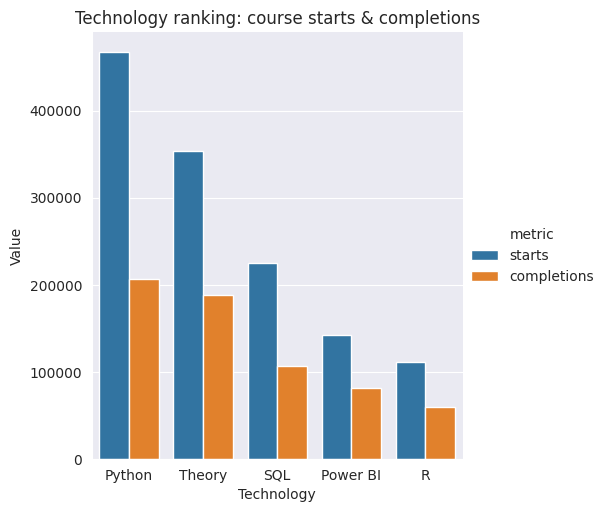

In [26]:
# Visualisation of the table above
df_tech_starts = tech_starts.reset_index().melt(id_vars='technology', value_vars=['starts', 'completions'], var_name='metric', value_name='value').sort_values(by='value', ascending=False)

# Extraction top 5 tech
top5_tech = tech_starts.reset_index()['technology'].head().to_list()

ax = sns.catplot(
    x='technology',
    y='value',
    # Limit our visualisation to 5 most popular technologies
    data=df_tech_starts.loc[df_tech_starts['technology'].isin(top5_tech)],
    kind='bar',
    hue='metric',
    legend=True
)

plt.title('Technology ranking: course starts & completions')
plt.xlabel('Technology')
plt.ylabel('Value')

After inspecting a bar plot with 5 most popular technologies, we clearly see the gap between number of starts and completions. Proceeding to the next issue - completion rate.

In [27]:
tech_rates = df_clean.groupby('technology')['completion_rate'].mean().sort_values(ascending=False).round(4)*100

tech_rates.head()

,completion_rate
technology,
DVC,62.09
ChatGPT,61.34
Theory,60.61
Git,60.16
GitHub,59.47


In [28]:
tech_rates.tail()

,completion_rate
technology,
Scala,25.94
BigQuery,23.03
Cursor,22.14
Redshift,21.65
n8n,11.98


Text(0.5, 29.140624999999986, 'Completion rate (%)')

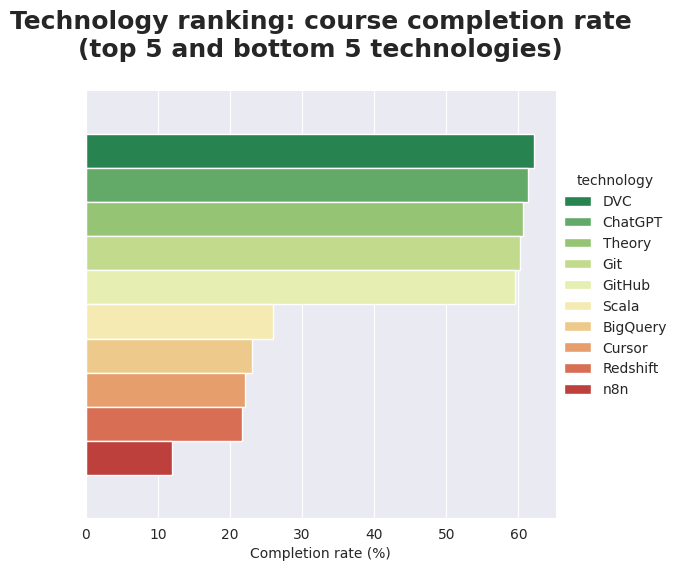

In [29]:
top_bottom_tech_completion = pd.concat([tech_rates.head(), tech_rates.tail()]).reset_index()

ax = sns.catplot(
    x='completion_rate',
    hue='technology',
    data= top_bottom_tech_completion,
    kind='bar',
    palette='RdYlGn_r'
)

plt.title('Technology ranking: course completion rate\n(top 5 and bottom 5 technologies)', fontsize=18, pad=25, fontweight='bold')
plt.xlabel('Completion rate (%)')

Text(0, 0.5, 'Completion rate')

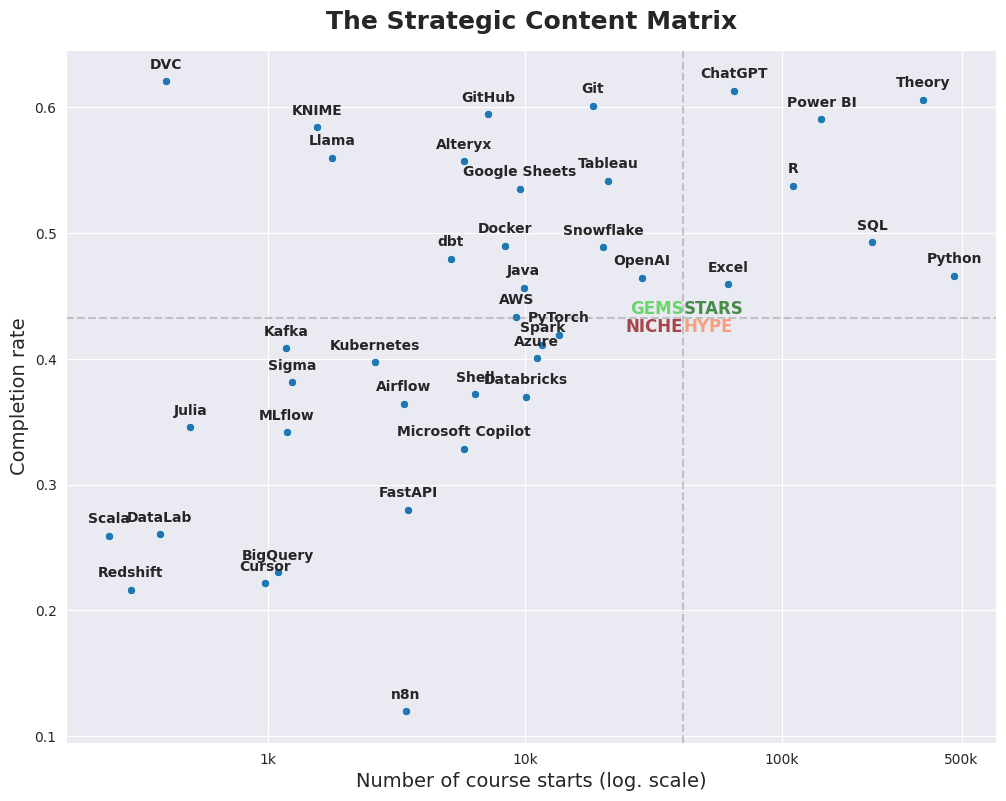

In [31]:
# Eisenhower-like matrix
tech_summary = df_clean.groupby('technology').agg({
    'starts' : 'sum',
    'completion_rate' : 'mean'
}).reset_index()

mean_starts = tech_summary['starts'].mean()
mean_rate = tech_summary['completion_rate'].mean()

# fig settings
plt.figure(figsize=(12,9))


# plot init.
ax = sns.scatterplot(
    x='starts',
    y='completion_rate',
    data= tech_summary,
    #hue='technology'
)

# point labels
for i in range(tech_summary.shape[0]):
    plt.text(
        x=tech_summary.starts[i],
        y=tech_summary.completion_rate[i] + 0.01,
        s=tech_summary.technology[i],
        fontsize=10,
        ha='center',
        fontweight='semibold'
    )

# x-scale to log
plt.xscale('log')

ticks = [1000, 10000, 100000, 500000]
ax.set_xticks(ticks)

ax.set_xticklabels([f'{int(x/1000)}k' for x in ticks])

# Dividing plot into 4 sections
plt.axvline(mean_starts, color='grey', linestyle='--', alpha=0.4)
plt.axhline(mean_rate, color='grey', linestyle='--', alpha=0.4)

# Labels for 4 quarters
plt.text(tech_summary.starts.mean(), tech_summary.completion_rate.mean(), 'STARS',
         color='darkgreen', fontsize=12, fontweight='bold', ha='left', va='bottom', alpha=0.7)

plt.text(tech_summary.starts.mean(), tech_summary.completion_rate.mean(), 'GEMS',
         color='limegreen', fontsize=12, fontweight='bold', ha='right', va='bottom', alpha=0.7)

plt.text(tech_summary.starts.mean(), tech_summary.completion_rate.mean(), 'HYPE',
         color='coral', fontsize=12, fontweight='bold', ha='left', va='top', alpha=0.7)


plt.text(tech_summary.starts.mean(), tech_summary.completion_rate.mean(), 'NICHE',
         color='darkred', fontsize=12, fontweight='bold', ha='right', va='top', alpha=0.7)


plt.title('The Strategic Content Matrix', fontsize=18, pad=15, fontweight='bold')
plt.xlabel('Number of course starts (log. scale)', fontsize=14)
plt.ylabel('Completion rate', fontsize=14)

This scatterplot evaluates technologies by comparing their popularity against their completion rate. Dashed lines represent the axes means, dividing plot into four sections:
- *STARS* - High volume, high completion rate.
- *GEMS* - High quality, low visibility.
- *HYPE* - High interest, high churn rate.
- *NICHE* - Low volume specialized or legacy content.
---

The Star Group includes technologies that are also most frequently mentioned in the media when speaking about data jobs - Python, SQL, Power BI, and Excel, and ChatGPT when it comes to AI. What's interesting about this group is the very high score of courses devoted to theory.

In the second group, the GEMS, we see technologies with very high completions rates, but without such recognition. Courses on such common technologies as Git/Github should be promoted more.
Technologies such as DVC and KNIME may not find as many takers, but they can certainly serve as models for well-designed course.

In last group, the NICHE, the most notable outlier is n8n, which exhibits a significant engagement gap - decent initial interest followed by the lowest completion rate. This suggeset a technical barrier or a major friction point (not met expectations).